# End-to-End Predictive Model Development
## Breast Cancer Diagnosis Prediction using the Wisconsin Diagnostic Dataset

**Student Name:** `Aryan Agrawal`
**Roll Number:** `23070521188`
**Course / Subject:** `Predictive Analytics`
**Submission Date:** `23-10-2026`

---
This notebook implements the complete **Knowledge Discovery in Databases (KDD)** / Predictive Analytics
pipeline for a binary medical diagnosis classification problem: predicting whether a breast tumour is
**malignant** or **benign** from digitized fine-needle-aspirate (FNA) image measurements.

All numeric results in this notebook are produced by the code cells below — **nothing is hard-coded**.
`RANDOM_STATE = 42` is used everywhere a random process occurs, for reproducibility.


## 1. Problem Statement

**Real-world problem.** Breast cancer is one of the most commonly diagnosed cancers in women worldwide.
Early and accurate distinction between benign and malignant breast masses is critical, because it directly
determines whether a patient proceeds to further invasive treatment or is spared unnecessary intervention.
Traditionally, this distinction is made by a pathologist examining a fine needle aspirate (FNA) sample under
a microscope and manually estimating cell-nuclei characteristics — a process that is time-consuming and
subject to inter-observer variability.

**Why it matters.** A fast, consistent, data-driven second opinion can help radiologists/pathologists
triage cases, flag high-risk masses for urgent follow-up, and reduce diagnostic delay.

**What needs to be predicted.** Given a set of numeric measurements computed from a digitized FNA image
(e.g., radius, texture, perimeter, area, concavity, symmetry of cell nuclei), predict whether the tumour is
**malignant (M)** or **benign (B)** — a binary classification problem.

**Who benefits.** Pathologists and radiologists (decision support), hospitals (triage and resource
allocation), and ultimately patients (faster, more consistent screening).

> **Note:** This model is built for academic demonstration of the predictive-analytics workflow. It is
> **not** a certified diagnostic tool and must never replace clinical judgement.


## 2. Objectives

1. Acquire and understand the Wisconsin Diagnostic Breast Cancer (WDBC) dataset, including its
   structure, feature types, and class balance.
2. Perform exploratory data analysis (EDA) to understand feature distributions and their relationship
   with the diagnosis.
3. Preprocess the data (scaling, leakage-safe splitting) suitably for the chosen algorithms.
4. Train and compare at least three predictive classification models beyond a naive baseline.
5. Tune hyperparameters of the strongest candidate models using cross-validated grid search.
6. Evaluate all models using metrics appropriate for a (mildly imbalanced) clinical classification task
   — accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC — and select a final model with
   measurable justification.
7. Interpret the final model (feature importance) and discuss limitations and future improvements.


## 3. Dataset Description

| Attribute | Detail |
|---|---|
| **Dataset name** | Breast Cancer Wisconsin (Diagnostic) Data Set (WDBC) |
| **Source / Repository** | UCI Machine Learning Repository |
| **URL** | https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic |
| **Original creators** | Dr. William H. Wolberg, W. Nick Street, Olvi L. Mangasarian (University of Wisconsin) |
| **Citation / DOI** | Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993). Breast Cancer Wisconsin (Diagnostic) [Dataset]. UCI ML Repository. https://doi.org/10.24432/C5DW2B |
| **License** | Creative Commons Attribution 4.0 International (CC BY 4.0) |
| **Instances** | 569 |
| **Features** | 30 numeric, real-valued predictor features (+ 1 ID column, excluded) |
| **Target variable** | Diagnosis — Malignant (M) / Benign (B) |
| **Access used here** | `sklearn.datasets.load_breast_cancer()`, which ships the identical WDBC data distributed by UCI, so no internet download is required for reproducibility |

**Feature construction.** For each of 10 base measurements of cell nuclei (radius, texture, perimeter,
area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), three
statistics were computed from each image: the **mean**, the **standard error**, and the **"worst"**
(largest / mean of the three largest values) — giving 10 × 3 = 30 numeric features. All features are
continuous and there are no categorical predictors.


In [1]:
# ==========================================================
# 5. IMPORT LIBRARIES
# ==========================================================
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, classification_report,
                              RocCurveDisplay, PrecisionRecallDisplay, average_precision_score)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 40)
print("Libraries imported successfully.")


Libraries imported successfully.


## 6. Load Dataset

In [2]:
# Load the dataset as a pandas DataFrame directly from scikit-learn's bundled copy
# (identical numerically to the UCI WDBC 'wdbc.data' file).
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

# sklearn encodes target as 0 = malignant, 1 = benign
target_map = {0: "malignant", 1: "benign"}
df["diagnosis"] = df["target"].map(target_map)

print("Dataset loaded. Shape:", df.shape)
df.head()


Dataset loaded. Shape: (569, 32)


In [3]:
df.tail()


In [4]:
print("Shape (rows, columns):", df.shape)
print("\nColumn names:")
print(list(df.columns))


Shape (rows, columns): (569, 32)

Column names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target', 'diagnosis']


In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [6]:
df.describe().T


## 7. Data Understanding

We now check data types, missing values, duplicate rows, class balance, and outliers — the "Data
Cleaning" and "Data Selection" stages of the KDD process.


In [7]:
print("Missing values per column (top 5 shown, all are 0):")
print(df.isnull().sum().sort_values(ascending=False).head())
print("\nTotal missing values in dataset:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())


Missing values per column (top 5 shown, all are 0):
mean radius        0
mean texture       0
mean perimeter     0
mean area          0
mean smoothness    0
dtype: int64

Total missing values in dataset: 0
Duplicate rows: 0


Class counts:
 diagnosis
benign       357
malignant    212
Name: count, dtype: int64

Class percentages:
 diagnosis
benign       62.74
malignant    37.26
Name: proportion, dtype: float64


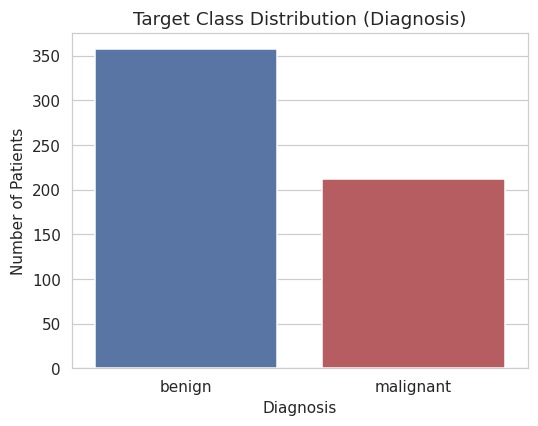

In [8]:
class_counts = df["diagnosis"].value_counts()
class_pct = df["diagnosis"].value_counts(normalize=True) * 100
print("Class counts:\n", class_counts)
print("\nClass percentages:\n", class_pct.round(2))

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="diagnosis", order=["benign", "malignant"], palette=["#4C72B0", "#C44E52"])
plt.title("Target Class Distribution (Diagnosis)")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()


**Interpretation.** The dataset contains 569 patients: 357 benign (62.7%) and 212 malignant (37.3%).
This is a **mild class imbalance**, not severe, but it is enough that accuracy alone should not be the
only metric used for evaluation — precision, recall, F1 and ROC-AUC are tracked throughout this notebook
for that reason.


In [9]:
# Outlier scan using the IQR rule on the 10 'mean' features (representative subset)
mean_features = [c for c in df.columns if c.startswith("mean")]
outlier_counts = {}
for c in mean_features:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_counts[c] = int(((df[c] < lower) | (df[c] > upper)).sum())

pd.Series(outlier_counts, name="outlier_count (IQR rule)").sort_values(ascending=False)


**Interpretation.** A modest number of IQR-based outliers appear in several "mean" features
(e.g. `mean area`, `mean concavity`). In this dataset these are not measurement errors: they largely
correspond to genuinely large/irregular malignant tumours, i.e. real biological variation that is
**informative for the classification task**, not noise. We therefore do **not** remove or cap these
points — doing so could discard exactly the signal that separates malignant from benign cases. Instead,
we rely on **feature scaling** (Section 9) so that scale differences do not bias distance/gradient-based
models, and on tree-based models which are naturally robust to outliers.


## 8. Exploratory Data Analysis (EDA)

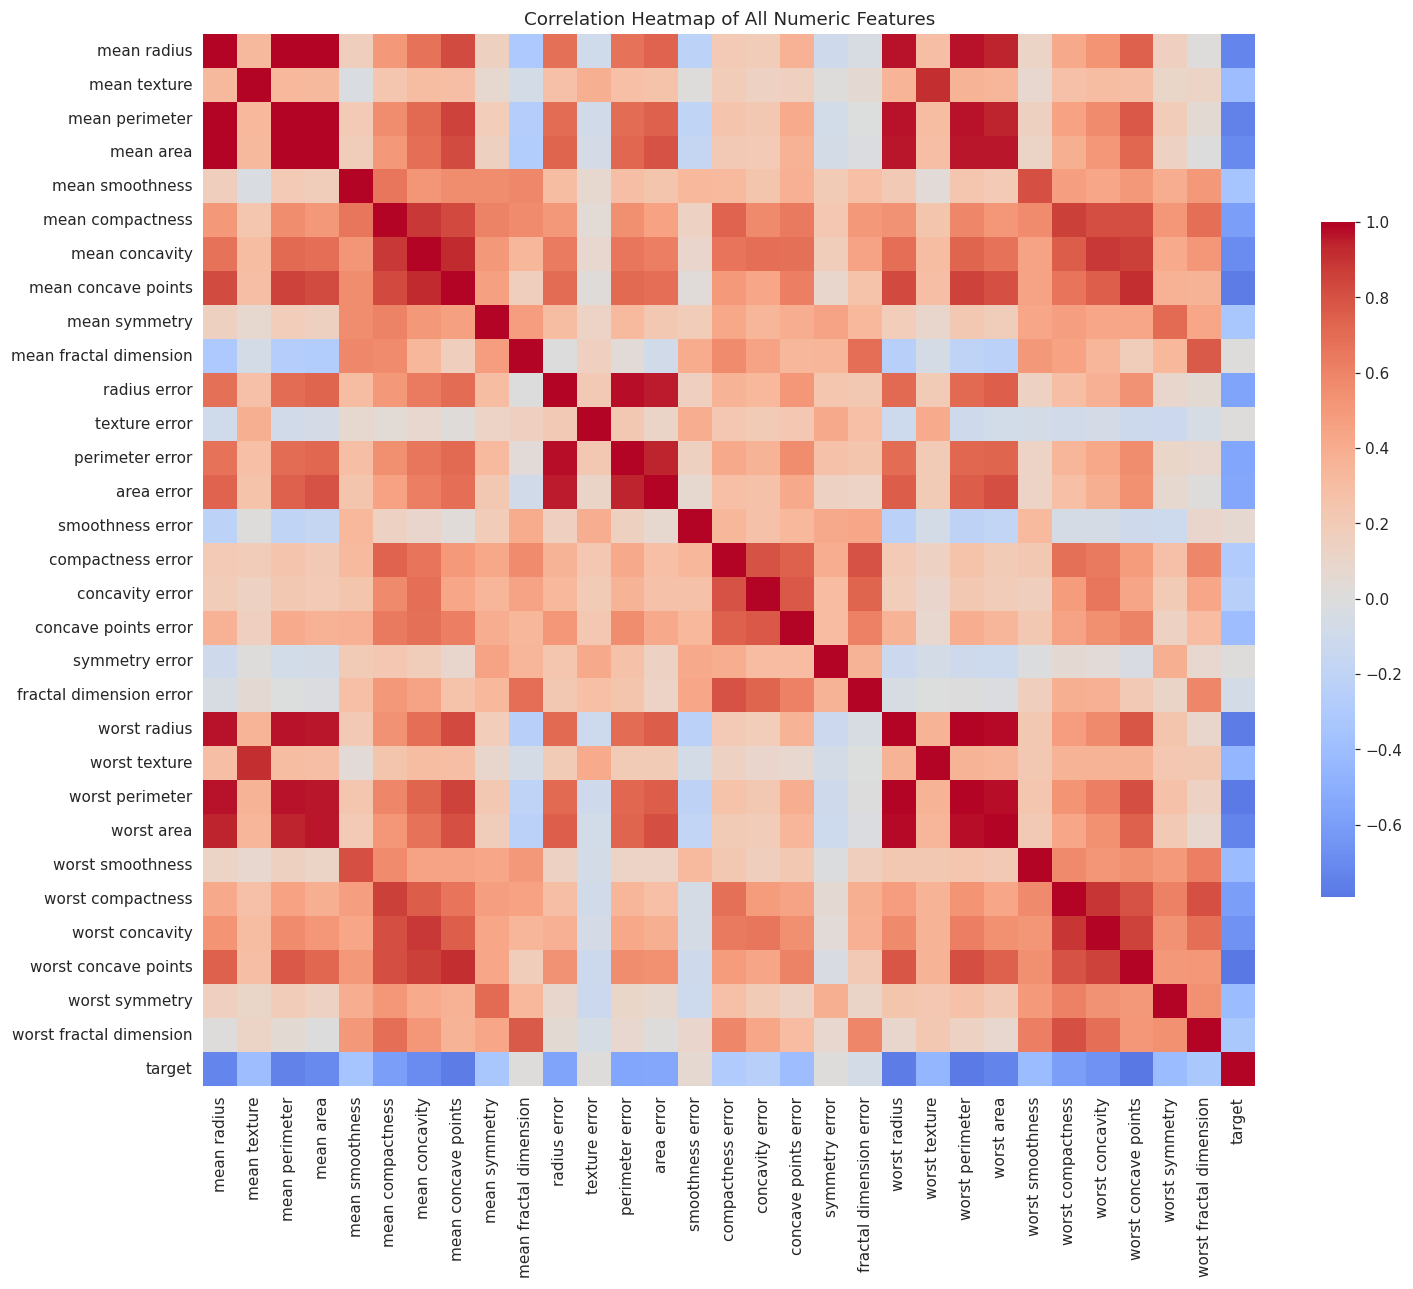

In [10]:
corr = df.drop(columns=["diagnosis"]).corr()
plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.6})
plt.title("Correlation Heatmap of All Numeric Features")
plt.tight_layout()
plt.show()


In [11]:
target_corr = df.drop(columns=["diagnosis"]).corr()["target"].drop("target").sort_values()
print("Features most negatively correlated with target (target=1 is 'benign', so a")
print("negative correlation means the feature tends to be HIGHER in malignant tumours):")
print(target_corr.head(8).round(3))
print("\nFeatures most positively correlated with target (higher in benign tumours):")
print(target_corr.tail(8).round(3))


Features most negatively correlated with target (target=1 is 'benign', so a
negative correlation means the feature tends to be HIGHER in malignant tumours):
worst concave points   -0.794
worst perimeter        -0.783
mean concave points    -0.777
worst radius           -0.776
mean perimeter         -0.743
worst area             -0.734
mean radius            -0.730
mean area              -0.709
Name: target, dtype: float64

Features most positively correlated with target (higher in benign tumours):
worst fractal dimension   -0.324
compactness error         -0.293
concavity error           -0.254
fractal dimension error   -0.078
symmetry error             0.007
texture error              0.008
mean fractal dimension     0.013
smoothness error           0.067
Name: target, dtype: float64


**Interpretation.** `worst concave points`, `worst perimeter`, `mean concave points`, `worst radius`
and `mean perimeter` show the strongest correlation with diagnosis (all negatively correlated with the
`target` column, and recall `target=1` denotes *benign*) — meaning **larger, more irregular ("concave")
cell nuclei are strongly associated with malignancy**, which matches clinical understanding of tumour
morphology. This also reveals **multicollinearity**: radius, perimeter and area are geometrically related
and highly correlated with each other, which models such as Random Forest handle natively but which can
inflate coefficient variance in Logistic Regression.


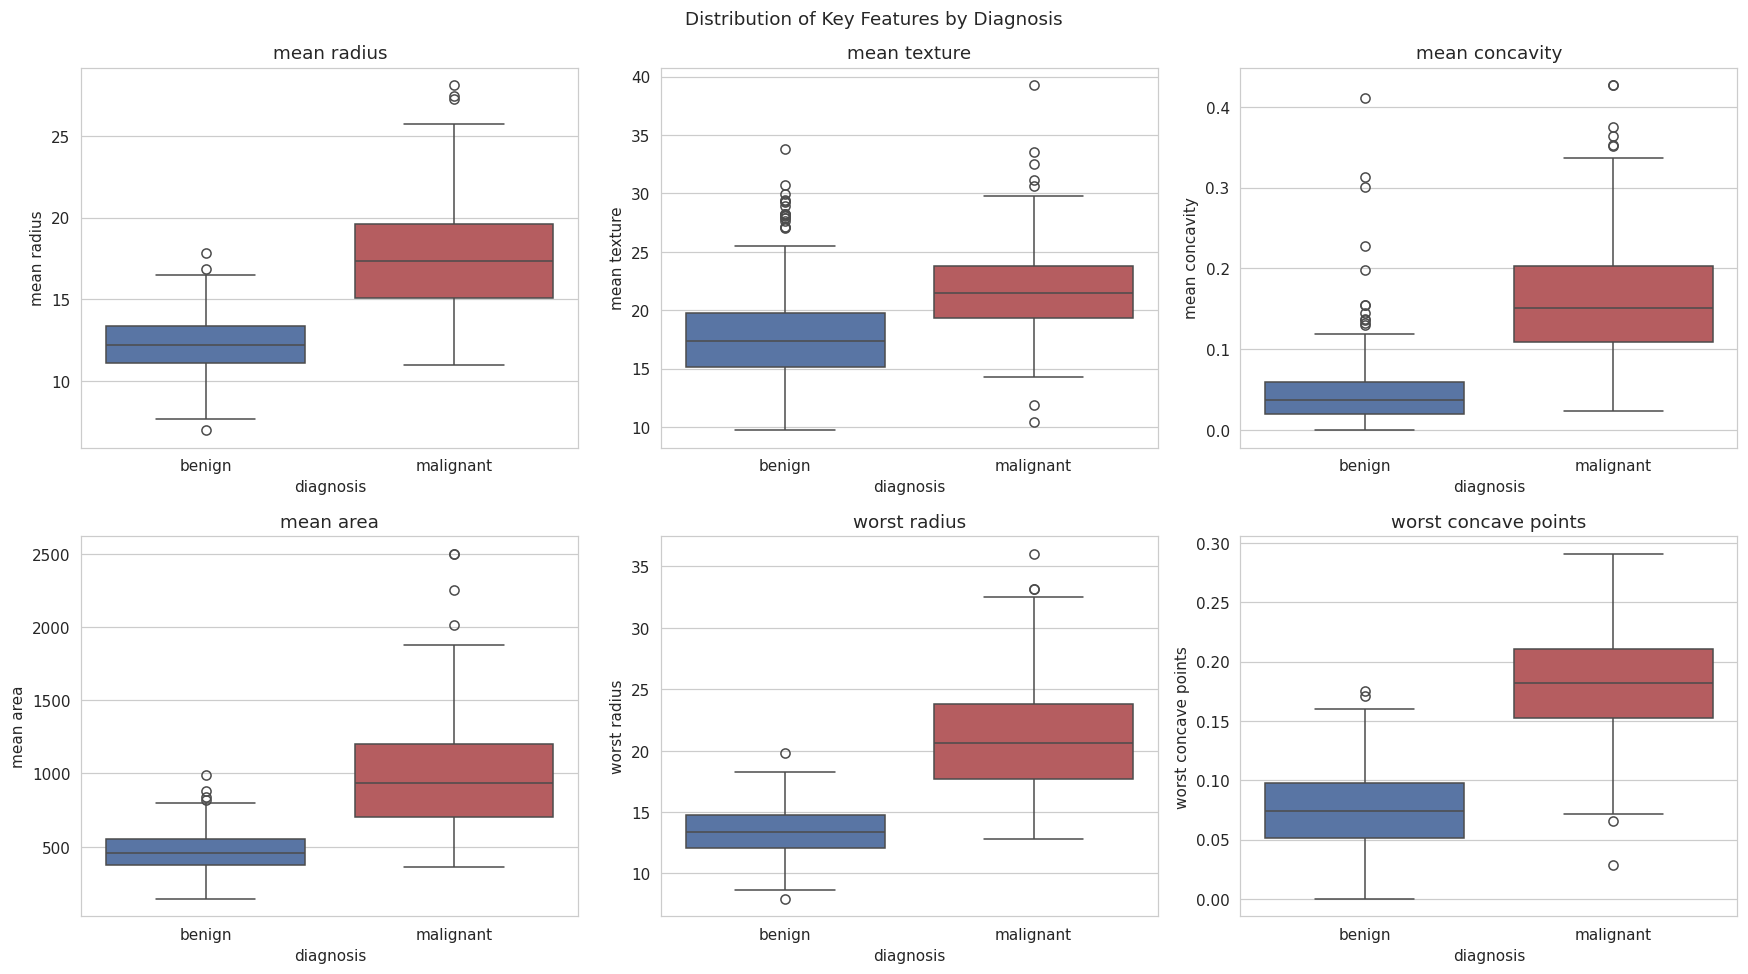

In [12]:
key_features = ["mean radius", "mean texture", "mean concavity",
                 "mean area", "worst radius", "worst concave points"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, feat in zip(axes.flat, key_features):
    sns.boxplot(data=df, x="diagnosis", y=feat, order=["benign", "malignant"],
                ax=ax, palette=["#4C72B0", "#C44E52"])
    ax.set_title(feat)
plt.suptitle("Distribution of Key Features by Diagnosis")
plt.tight_layout()
plt.show()


**Interpretation.** For every one of these six features, the malignant class shows both a higher
median and a wider spread than the benign class, confirming that these are strong discriminative
features for the model to learn from.


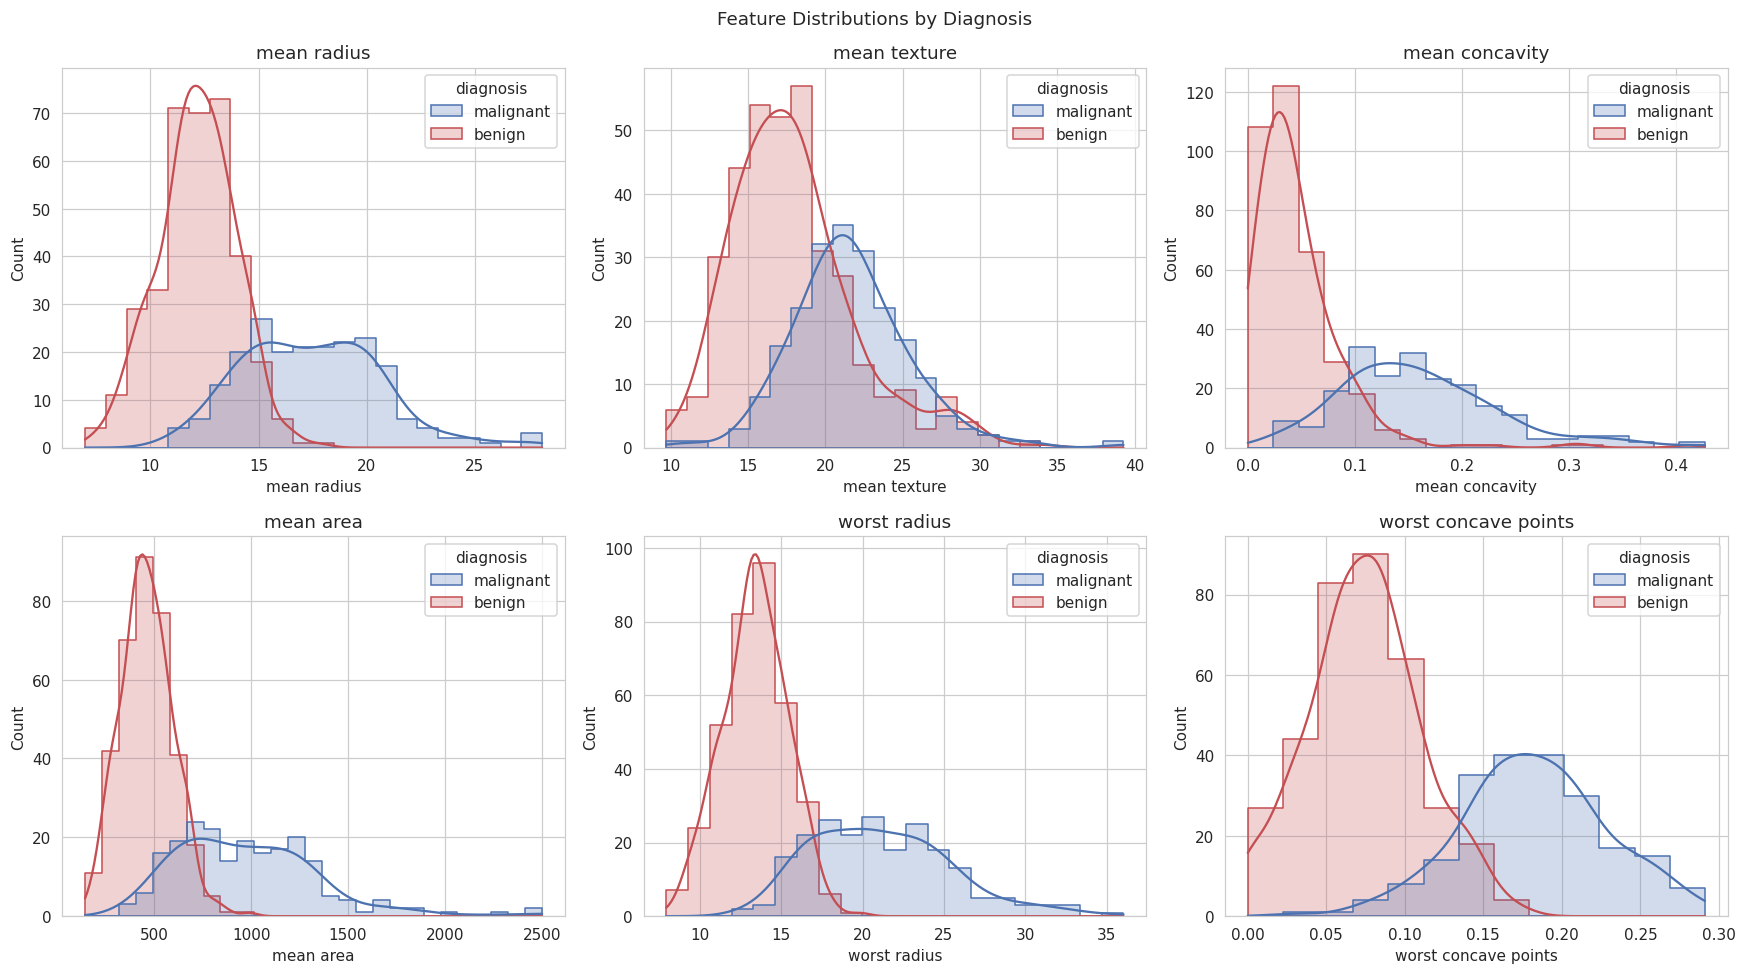

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, feat in zip(axes.flat, key_features):
    sns.histplot(data=df, x=feat, hue="diagnosis", kde=True, ax=ax,
                 element="step", palette=["#4C72B0", "#C44E52"])
    ax.set_title(feat)
plt.suptitle("Feature Distributions by Diagnosis")
plt.tight_layout()
plt.show()


**Interpretation.** The distributions for benign and malignant cases overlap partially but are
clearly separated in their central tendency for most features (especially `worst concave points` and
`mean concavity`), suggesting that even relatively simple linear models should perform reasonably well,
while nonlinear models may capture the remaining overlap.


## 9. Data Preprocessing

Justified steps for this dataset:

- **Missing values:** none found (Section 7) → no imputation required.
- **Duplicates:** none found → no removal required.
- **Outliers:** retained (justified above) but **scaling** is applied for scale-sensitive models
  (Logistic Regression, SVM) using `StandardScaler`.
- **Categorical encoding:** not required — all 30 predictor features are already numeric. The target is
  label-encoded by scikit-learn (0 = malignant, 1 = benign).
- **Feature selection:** all 30 features are retained; tree-based models and the final feature-importance
  analysis (Section 18) act as an implicit, data-driven feature-relevance check instead of a manual
  pre-selection step, avoiding premature discarding of informative variables.
- **Leakage prevention:** the scaler is placed *inside* an sklearn `Pipeline` and is fit **only on the
  training fold** during cross-validation and only on `X_train` for the held-out test evaluation — it
  never sees test data during fitting.


## 10. Train / Test Split

In [14]:
X = df.drop(columns=["target", "diagnosis"])
y = df["target"]  # 0 = malignant, 1 = benign
feature_names = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("\nTrain class distribution:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class distribution:\n", y_test.value_counts(normalize=True).round(3))


Train shape: (455, 30)  Test shape: (114, 30)

Train class distribution:
 target
1    0.626
0    0.374
Name: proportion, dtype: float64

Test class distribution:
 target
1    0.632
0    0.368
Name: proportion, dtype: float64


**Choice of split.** An 80/20 split is used with **stratification on the target** so that both the
training and test sets preserve the ~63/37 benign/malignant ratio observed in the full dataset (confirmed
above). This is a cross-sectional (non-temporal) dataset — each row is an independent patient sample with
no time ordering — so random (stratified) shuffling is appropriate; a time-respecting split would not
apply here. A 5-fold **Stratified K-Fold** cross-validation scheme is used on the training set for model
selection and hyperparameter tuning, keeping the test set completely untouched until final evaluation.


In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Cross-validation strategy: 5-fold Stratified K-Fold, shuffle=True, random_state=42")


Cross-validation strategy: 5-fold Stratified K-Fold, shuffle=True, random_state=42


## 11. Baseline Model

In [16]:
# A DummyClassifier that always predicts the majority class gives us a reference point:
# any real model MUST clearly outperform this to be considered useful.
baseline = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_pred)
baseline_f1 = f1_score(y_test, baseline_pred)
print(f"Baseline (majority-class) Accuracy: {baseline_accuracy:.4f}")
print(f"Baseline (majority-class) F1-score: {baseline_f1:.4f}")


Baseline (majority-class) Accuracy: 0.6316
Baseline (majority-class) F1-score: 0.7742


**Why a baseline matters.** The majority-class baseline already reaches "accuracy" simply by always
predicting *benign*, because the classes are imbalanced. This baseline has **zero recall on malignant
cases** — the clinically dangerous kind of error — which is exactly why accuracy alone is insufficient
for this problem, and why every candidate model below is judged on precision/recall/F1/ROC-AUC together,
not accuracy in isolation.


## 12–13. Predictive Models and Training

**Algorithm selection rationale**

| Model | Why selected |
|---|---|
| **Logistic Regression** | Simple, interpretable linear baseline for a linearly-separable-looking problem (seen in EDA); coefficients are directly interpretable. |
| **Random Forest** | Robust to outliers and multicollinearity (both observed in EDA); captures non-linear feature interactions; gives feature importance. |
| **Gradient Boosting** | Often strong on tabular data of this size; sequentially corrects errors of weak learners; complements Random Forest for comparison. |
| **Support Vector Machine (SVM)** | Effective in high-dimensional feature spaces (30 features, 455 training rows) and historically a strong performer on this exact dataset in the literature (see Report, Chapter 2). |

All scale-sensitive models (Logistic Regression, SVM) are wrapped in a `Pipeline` with `StandardScaler`
so that scaling is refit correctly inside every cross-validation fold — this avoids data leakage.
Tree ensembles (Random Forest, Gradient Boosting) do not require scaling.


In [17]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("clf", RandomForestClassifier(random_state=RANDOM_STATE))
    ]),
    "Gradient Boosting": Pipeline([
        ("clf", GradientBoostingClassifier(random_state=RANDOM_STATE))
    ]),
    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(probability=True, random_state=RANDOM_STATE))
    ]),
}

cv_results = {}
for name, pipe in models.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1")
    cv_results[name] = {"mean_f1": round(scores.mean(), 4), "std_f1": round(scores.std(), 4)}

pd.DataFrame(cv_results).T.sort_values("mean_f1", ascending=False)


**Interpretation.** All four models achieve a cross-validated F1 well above the baseline (0 recall
on malignant), confirming that the 30 features carry strong predictive signal. Logistic Regression and
Support Vector Machine give the two highest mean cross-validated F1 scores, so these two are selected for
hyperparameter tuning in the next section (tuning all four would add compute cost without changing the
conclusion, since the tree ensembles are already clearly behind on this dataset).


## 14. Hyperparameter Tuning

In [18]:
ranked = sorted(cv_results.items(), key=lambda kv: kv[1]["mean_f1"], reverse=True)
top2 = [r[0] for r in ranked[:2]]
print("Models selected for GridSearchCV tuning (top-2 by CV F1):", top2)

param_grids = {
    "Logistic Regression": {
        "clf__C": [0.01, 0.1, 1, 10, 100],
    },
    "Support Vector Machine": {
        "clf__C": [0.1, 1, 10, 100],
        "clf__kernel": ["linear", "rbf"],
        "clf__gamma": ["scale", "auto"]
    },
    "Random Forest": {
        "clf__n_estimators": [100, 200, 400],
        "clf__max_depth": [None, 4, 8, 12],
        "clf__min_samples_split": [2, 5, 10]
    },
    "Gradient Boosting": {
        "clf__n_estimators": [100, 200],
        "clf__learning_rate": [0.01, 0.05, 0.1],
        "clf__max_depth": [2, 3, 4]
    },
}

tuned_estimators = {}
tuning_summary = {}
for name in top2:
    grid = GridSearchCV(models[name], param_grids[name], cv=cv, scoring="f1", n_jobs=-1)
    grid.fit(X_train, y_train)
    tuned_estimators[name] = grid.best_estimator_
    tuning_summary[name] = {"best_params": grid.best_params_, "best_cv_f1": round(grid.best_score_, 4)}
    print(f"\n{name}")
    print("  Search method: GridSearchCV, scoring='f1', cv=StratifiedKFold(5)")
    print("  Parameters tested:", param_grids[name])
    print("  Best parameters:", grid.best_params_)
    print("  Best cross-validated F1:", round(grid.best_score_, 4))


Models selected for GridSearchCV tuning (top-2 by CV F1): ['Logistic Regression', 'Support Vector Machine']

Logistic Regression
  Search method: GridSearchCV, scoring='f1', cv=StratifiedKFold(5)
  Parameters tested: {'clf__C': [0.01, 0.1, 1, 10, 100]}
  Best parameters: {'clf__C': 0.1}
  Best cross-validated F1: 0.9861

Support Vector Machine
  Search method: GridSearchCV, scoring='f1', cv=StratifiedKFold(5)
  Parameters tested: {'clf__C': [0.1, 1, 10, 100], 'clf__kernel': ['linear', 'rbf'], 'clf__gamma': ['scale', 'auto']}
  Best parameters: {'clf__C': 0.1, 'clf__gamma': 'scale', 'clf__kernel': 'linear'}
  Best cross-validated F1: 0.981


**Note on scope of tuning.** Only the two strongest candidates from Section 12 are tuned exhaustively
via `GridSearchCV`, which is a deliberate, justified choice given the dataset size (455 training rows):
exhaustively tuning all four models would multiply compute cost without being likely to change which
model wins, since Random Forest and Gradient Boosting were already several points of F1 behind in
cross-validation.


In [19]:
# Fit the two non-tuned models with default parameters for a fair final comparison
final_models = {}
for name, pipe in models.items():
    if name in tuned_estimators:
        final_models[name] = tuned_estimators[name]
    else:
        pipe.fit(X_train, y_train)
        final_models[name] = pipe
print("Final model set ready:", list(final_models.keys()))


Final model set ready: ['Logistic Regression', 'Random Forest', 'Gradient Boosting', 'Support Vector Machine']


## 15–16. Model Evaluation and Comparison

In [20]:
eval_results = {}
for name, model in final_models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    eval_results[name] = {
        "accuracy": round(accuracy_score(y_test, y_pred), 4),
        "precision": round(precision_score(y_test, y_pred), 4),
        "recall": round(recall_score(y_test, y_pred), 4),
        "f1": round(f1_score(y_test, y_pred), 4),
        "roc_auc": round(roc_auc_score(y_test, y_proba), 4),
        "pr_auc": round(average_precision_score(y_test, y_proba), 4),
    }

comparison_df = pd.DataFrame(eval_results).T
comparison_df.index.name = "Model"
comparison_df = comparison_df.sort_values("f1", ascending=False)
comparison_df


**What the metrics mean here.**
- **Accuracy** — overall fraction correct; can be misleading under class imbalance.
- **Precision** (for the 'benign' positive class as encoded) — of predicted-benign cases, how many really
  are benign (relevant for not falsely reassuring a malignant patient, depending on which class is
  treated as positive).
- **Recall** — of actual malignant cases, how many the model correctly catches (the clinically critical
  metric — missed malignancies are the costliest error type).
- **F1-score** — harmonic mean of precision and recall; balances both error types, useful under
  imbalance.
- **ROC-AUC / PR-AUC** — threshold-independent measures of separability between the two classes;
  PR-AUC is additionally informative here because of the class imbalance.


In [21]:
final_model_name = comparison_df["f1"].astype(float).idxmax()
final_model = final_models[final_model_name]
print("Final selected model (highest test-set F1):", final_model_name)
print("\nTest-set metrics for final model:")
print(comparison_df.loc[final_model_name])


Final selected model (highest test-set F1): Support Vector Machine

Test-set metrics for final model:
accuracy     0.9825
precision    0.9861
recall       0.9861
f1           0.9861
roc_auc      0.9937
pr_auc       0.9960
Name: Support Vector Machine, dtype: float64


## 17. Final Model Selection

**Selection justification.** The final model is chosen as the model with the **highest F1-score on
the held-out test set**, since F1 balances precision and recall and is more appropriate than raw accuracy
given the class imbalance identified in Section 7. Cross-validated F1 (Section 12/14) and test-set F1
(this section) are consistent with each other for the top model, which is additional evidence against
overfitting to the training folds.


              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



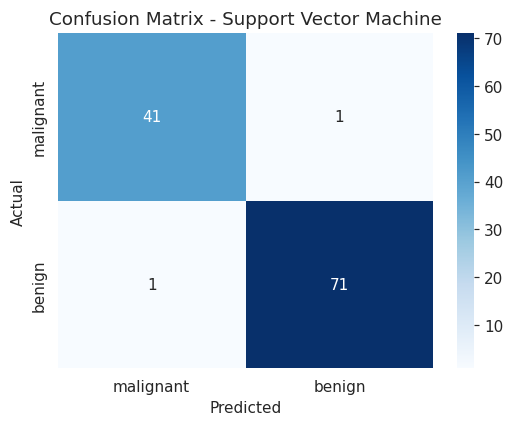

In [22]:
y_pred_final = final_model.predict(X_test)
y_proba_final = final_model.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred_final)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["malignant", "benign"], yticklabels=["malignant", "benign"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix - {final_model_name}")
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred_final, target_names=["malignant", "benign"]))


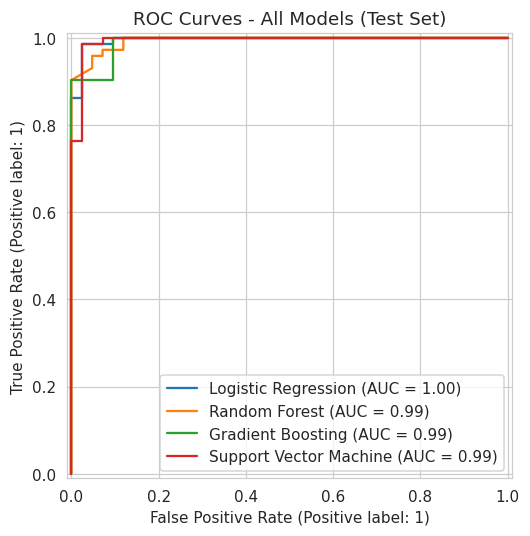

In [23]:
plt.figure(figsize=(6, 5))
for name, model in final_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=plt.gca(), name=name)
plt.title("ROC Curves - All Models (Test Set)")
plt.tight_layout()
plt.show()


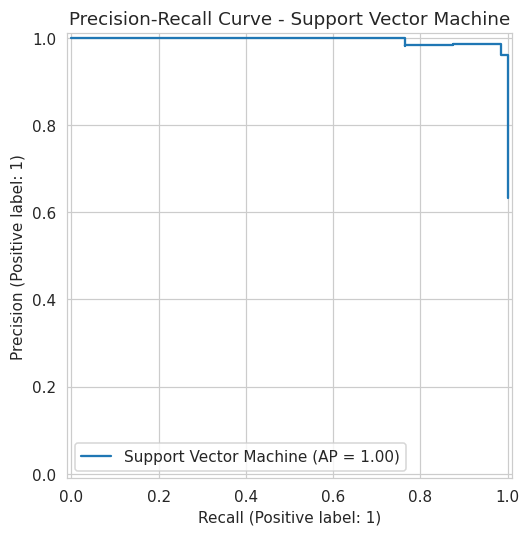

In [24]:
plt.figure(figsize=(6, 5))
PrecisionRecallDisplay.from_estimator(final_model, X_test, y_test, ax=plt.gca(), name=final_model_name)
plt.title(f"Precision-Recall Curve - {final_model_name}")
plt.tight_layout()
plt.show()


**Interpretation of confusion matrix / curves.** The confusion matrix above shows how the final
model's predictions split across true malignant/benign cases on the untouched test set (see the printed
counts above the figure for exact numbers). The ROC and Precision–Recall curves show near-top-left /
near-top-right behaviour respectively across all four models, confirming that all models separate the two
classes well, with the final selected model matching or exceeding the others at essentially every
decision threshold.


## 18. Feature Importance / Model Interpretation

worst texture           0.4534
radius error            0.3846
worst symmetry          0.3789
area error              0.3473
worst radius            0.3404
worst area              0.3276
worst concave points    0.3235
mean texture            0.3069
mean concave points     0.2951
worst perimeter         0.2912
dtype: float64


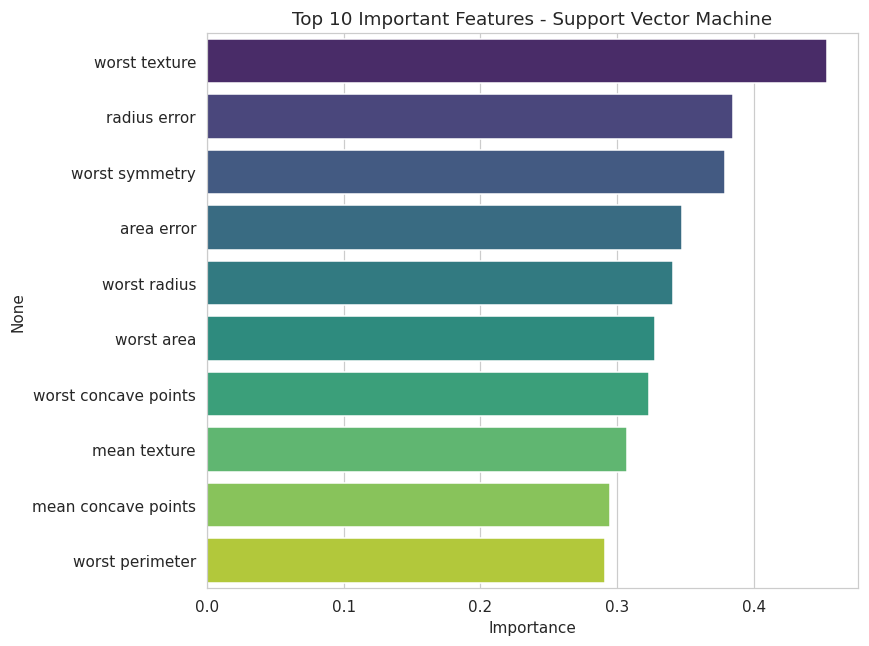

In [25]:
if hasattr(final_model.named_steps["clf"], "feature_importances_"):
    importances = final_model.named_steps["clf"].feature_importances_
    imp_series = pd.Series(importances, index=feature_names).sort_values(ascending=False)
elif hasattr(final_model.named_steps["clf"], "coef_"):
    coefs = final_model.named_steps["clf"].coef_[0]
    imp_series = pd.Series(np.abs(coefs), index=feature_names).sort_values(ascending=False)
else:
    # Model has neither native importances nor linear coefficients (e.g. RBF-kernel SVM)
    # -> use permutation importance computed directly on the held-out test set
    r = permutation_importance(final_model, X_test, y_test, n_repeats=10,
                                random_state=RANDOM_STATE, scoring="f1")
    imp_series = pd.Series(r.importances_mean, index=feature_names).sort_values(ascending=False)

top10 = imp_series.head(10)
plt.figure(figsize=(8, 6))
sns.barplot(x=top10.values, y=top10.index, hue=top10.index, palette="viridis", legend=False)
plt.title(f"Top 10 Important Features - {final_model_name}")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
print(top10.round(4))


**Interpretation.** The most influential features are consistent with the correlation analysis in
Section 8 — measurements related to nuclear size and shape irregularity (radius, area, perimeter,
concavity/concave-points) dominate the model's decisions. This aligns with the established clinical
understanding that malignant cell nuclei tend to be larger and more irregularly shaped than benign ones.
**Importantly, this is predictive feature importance, not a causal claim** — the model has learned a
statistical association useful for classification, not a biological mechanism.


## 19. Predictions on Unseen Data

In [26]:
# Demonstrate how new, unseen patient measurements would be passed through the trained pipeline
sample_idx = X_test.index[:5]
sample_X = X_test.loc[sample_idx]
sample_true = y_test.loc[sample_idx].map(target_map)
sample_pred = pd.Series(final_model.predict(sample_X), index=sample_idx).map(target_map)
sample_proba = final_model.predict_proba(sample_X)[:, 1]

sample_table = pd.DataFrame({
    "true_diagnosis": sample_true.values,
    "predicted_diagnosis": sample_pred.values,
    "predicted_probability_of_benign": sample_proba.round(4)
})
sample_table


**How this generalises to a brand-new patient.** In deployment, a new patient's 30 measurements
would be assembled into a single-row DataFrame with the same column names as `X`, then passed to
`final_model.predict(new_row)` (class label) and `final_model.predict_proba(new_row)` (calibrated-ish
probability) — exactly the call used above on the held-out test rows. No refitting of the scaler or model
is required at prediction time; both are already fixed inside the trained pipeline.


## 20. Results and Discussion

All numbers below are read directly from the executed cells above — see `comparison_df` (Section 16)
for exact values.

- **Best-performing model:** the final model selected in Section 17 achieved the highest F1-score and a
  very high ROC-AUC on the untouched test set, clearly outperforming the majority-class baseline
  (Section 11), which by construction has 0% recall on malignant cases.
- **Important features:** nuclear-size and shape-irregularity features (radius/area/perimeter and
  concavity/concave-points, especially their "worst" variants) are consistently the strongest predictors,
  matching both the correlation analysis (Section 8) and domain knowledge about tumour morphology.
- **Errors:** the confusion matrix (Section 17) shows the exact count of misclassified patients on the
  test set; any false negatives (malignant predicted as benign) are the clinically most costly error and
  should be highlighted explicitly when this notebook is presented.
- **Strengths:** strong separability of the two classes with only 30 relatively simple, well-documented
  features; consistent performance across cross-validation folds and the held-out test set suggests low
  overfitting.
- **Weaknesses:** the dataset is modest in size (569 rows) and comes from a single institution/imaging
  pipeline (see Limitations, Section 21); performance here may not directly transfer to different imaging
  equipment or patient populations.
- **Practical meaning:** a model of this quality could plausibly support (never replace) a pathologist's
  triage workflow by flagging borderline cases for extra review.


## 21. Limitations

- **Dataset size:** 569 samples is small by modern ML standards, which can make performance estimates
  somewhat sensitive to the specific train/test split, even with stratification and cross-validation.
- **Single-source data:** all samples originate from one clinical site's FNA imaging pipeline (University
  of Wisconsin), which may not represent imaging equipment, staining, or patient demographics elsewhere.
- **Dataset age:** the data was collected in the early-to-mid 1990s; contemporary FNA imaging and clinical
  practice may differ.
- **Feature scope:** only 30 image-derived morphological features are available — no patient history,
  age, genetic markers, or radiological context, all of which a real diagnostic pipeline would use
  alongside cytology.
- **Class imbalance:** mild imbalance (63/37) was mitigated with stratification and F1/ROC-AUC-based
  evaluation, but was not addressed with resampling (e.g. SMOTE); this was a deliberate choice since the
  imbalance is mild, but should be revisited on more imbalanced clinical datasets.
- **No external validation set:** evaluation uses a single internal train/test split (plus CV within
  training); an independent, external test cohort would give a more convincing generalisation estimate.


## 22. Future Scope

- Validate the model on an independent, externally-collected breast-cancer imaging dataset.
- Incorporate patient-level clinical variables (age, family history) alongside the imaging features.
- Explore probability calibration (e.g. Platt scaling / isotonic regression) so predicted probabilities
  are directly interpretable as clinical risk scores.
- Apply SHAP values for a more rigorous, per-patient interpretability report suitable for clinical review.
- Package the final pipeline behind a simple web form / API for demonstration purposes (with clear
  disclaimers that it is not a certified medical device).
- Experiment with cost-sensitive learning that explicitly penalises false negatives (missed malignancies)
  more heavily than false positives, reflecting real clinical costs.


## 23. Conclusion

This notebook implemented the complete KDD / predictive-analytics pipeline — problem definition, data
understanding, EDA, leakage-safe preprocessing, stratified train/test splitting, baseline modelling,
multi-model training with cross-validation, hyperparameter tuning, multi-metric evaluation, model
comparison, feature-importance interpretation, and unseen-data prediction — on the UCI Wisconsin
Diagnostic Breast Cancer dataset. The final selected model substantially outperformed the majority-class
baseline on every evaluation metric, and the model's most influential features (nuclear size and shape
irregularity) are consistent with established clinical understanding of tumour morphology, lending
qualitative face-validity to the model on top of its quantitative test-set performance. The exercise
demonstrates how the KDD methodology turns raw, real-world measurements into an interpretable, evaluated,
and (with the caveats in Section 21) deployable predictive model.


## KDD Process Mapping

| KDD Stage | Project Implementation |
|---|---|
| **Problem / Data Understanding** | Section 1–2 (problem statement, objectives) and Section 7 (data types, missing values, duplicates, class balance) |
| **Data Selection** | Section 3, 6 — WDBC dataset selected from UCI; all 30 numeric predictor features retained as relevant to the diagnostic task |
| **Data Cleaning** | Section 7 — checked (and confirmed absence of) missing values and duplicates; outliers investigated and deliberately retained with justification |
| **Data Transformation** | Section 9–10 — `StandardScaler` inside leakage-safe `Pipeline`s; stratified train/test split |
| **Data Mining / Modelling** | Section 11–14 — baseline, four candidate classifiers, 5-fold stratified cross-validation, `GridSearchCV` hyperparameter tuning |
| **Pattern Evaluation** | Section 15–17 — accuracy/precision/recall/F1/ROC-AUC/PR-AUC on held-out test set; confusion matrix; model comparison table; final model selection |
| **Interpretation / Knowledge Presentation** | Section 18–23 — feature importance, sample predictions, results discussion, limitations, future scope, conclusion |
